Бинарная классификация (heart_disease_dataset)

## 1. Импорт библиотек и загрузка данных

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style='whitegrid')
plt.rcParams['font.size'] = 11
pd.set_option('display.width', 150)
pd.set_option('displa y.max_columns', None)

file_path = 'Heart_Disease_and_Hospitals.csv'

df = pd.read_csv(file_path)

print(f"Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов\n")
print("Первые 5 строк датасета:")
display(df.head())

print("\nИнформация о типах данных и заполненности столбцов:")
df.info()

target_col = 'heart_disease'
unique_targets = df[target_col].unique()

print(f"\nУникальные значения целевого признака '{target_col}': {unique_targets}")
assert len(unique_targets) == 2, "Ошибка: целевой признак не является бинарным!"

counts = df[target_col].value_counts()
percents = df[target_col].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    'Количество': counts,
    'Доля (%)': percents.round(2)
})
target_summary.index = target_summary.index.map({0: '0 (Здоров)', 1: '1 (Болен)'})

print("\nРаспределение целевой переменной:")
print(target_summary.to_string())

Размер датасета: 10000 строк, 15 столбцов

Первые 5 строк датасета:


,full_name,age,country,state,blood_pressure,cholesterol,bmi,glucose_level,gender,first_name,last_name,hospital,treatment,treatment_date,heart_disease
0,Alice Johnson,21,USA,Utah,138.068129,270.564349,36.101427,63.487954,Female,Alice,Johnson,Starlight Hospital,Physiotherapy,2021-07-07 21:23:23.542872956,1
1,Bob Williams,44,USA,North Dakota,100.383639,160.910030,14.330471,187.008977,Female,Bob,Williams,Maple Leaf Hospital,Counseling,2023-09-13 07:31:37.167014532,0
2,Oliver Jones,22,USA,Iowa,145.618318,208.490251,20.277098,35.903576,Female,Oliver,Jones,Crossroads Health Center,Medication,2019-11-22 03:56:29.389793943,0
3,Quinn Davis,19,USA,Louisiana,152.577870,348.153738,62.712693,31.495166,Female,Quinn,Davis,Springfield General Hospital,Counseling,2021-10-09 23:10:16.253672680,1
4,Alice Martinez,64,USA,Massachusetts,111.793570,200.628925,14.468485,154.513129,Female,Alice,Martinez,Valley View Hospital,Rehabilitation,2018-03-16 04:43:59.950843739,1



Информация о типах данных и заполненности столбцов:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   full_name       10000 non-null  object 
 1   age             10000 non-null  int64  
 2   country         10000 non-null  object 
 3   state           10000 non-null  object 
 4   blood_pressure  10000 non-null  float64
 5   cholesterol     10000 non-null  float64
 6   bmi             10000 non-null  float64
 7   glucose_level   10000 non-null  float64
 8   gender          10000 non-null  object 
 9   first_name      10000 non-null  object 
 10  last_name       10000 non-null  object 
 11  hospital        10000 non-null  object 
 12  treatment       10000 non-null  object 
 13  treatment_date  10000 non-null  object 
 14  heart_disease   10000 non-null  int64  
dtypes: float64(4), int64(2), object(9)
memory usage: 1.1+ MB

Уникальные 

## 2. Очистка датасета от пропусков, выбросов и отбор признаков

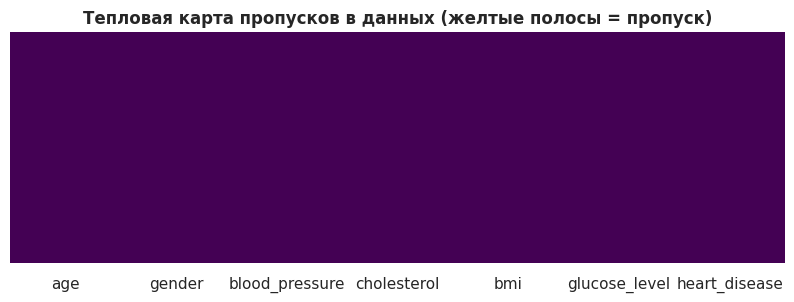

Всего пропусков (NaN): 0
Удалено строк с отрицательным сахаром и физическими аномалиями: 3922


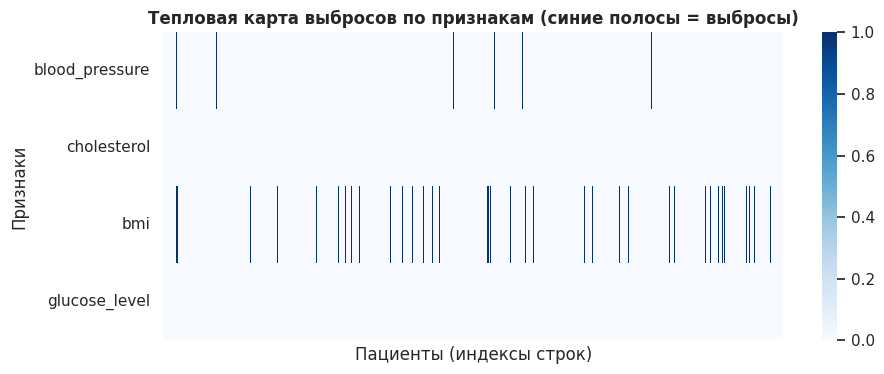

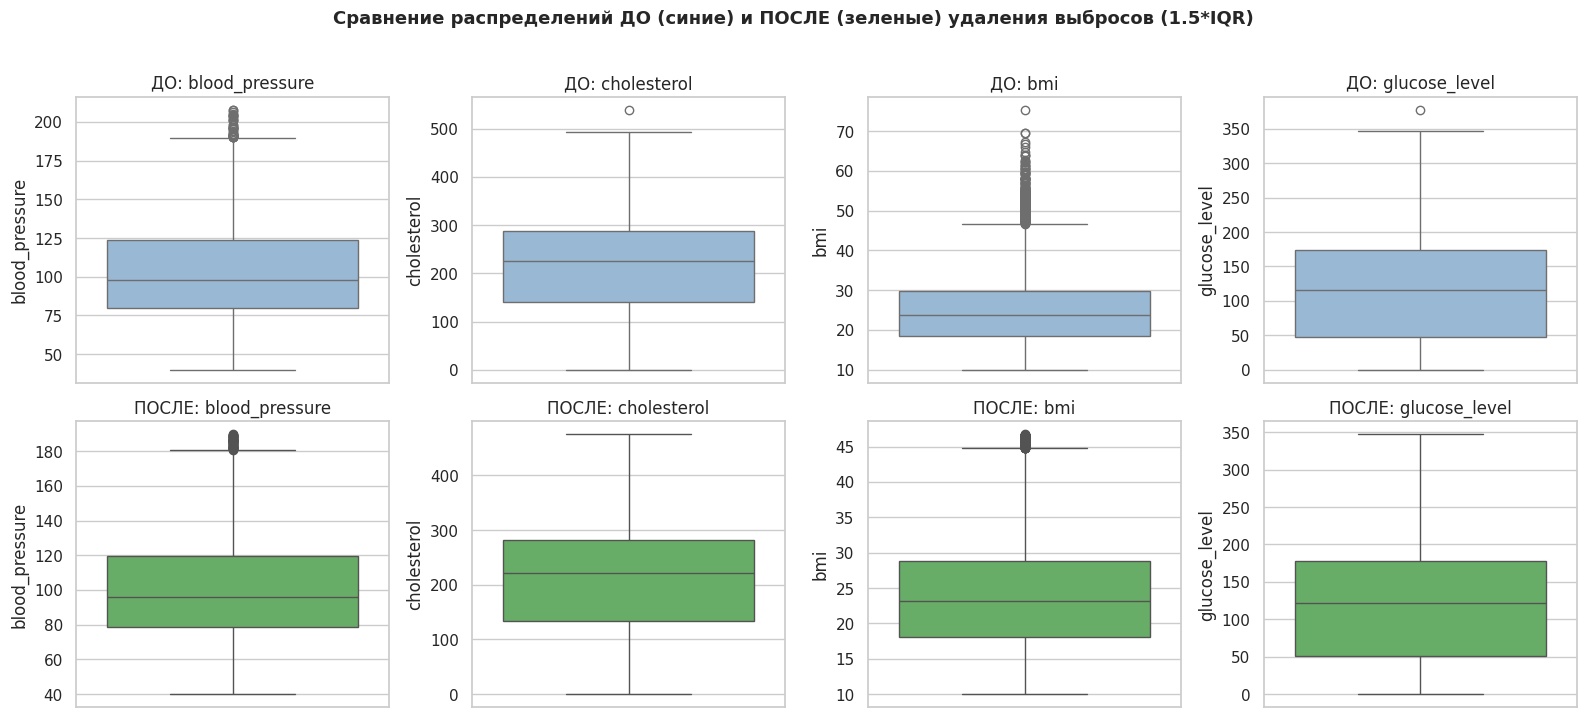

Удалено строк со статистическими выбросами (1.5*IQR): 324
Итоговый размер чистой выборки: 5754 строк

Баланс классов (0 - здоров, 1 - болен):
heart_disease
1    53.25
0    46.75


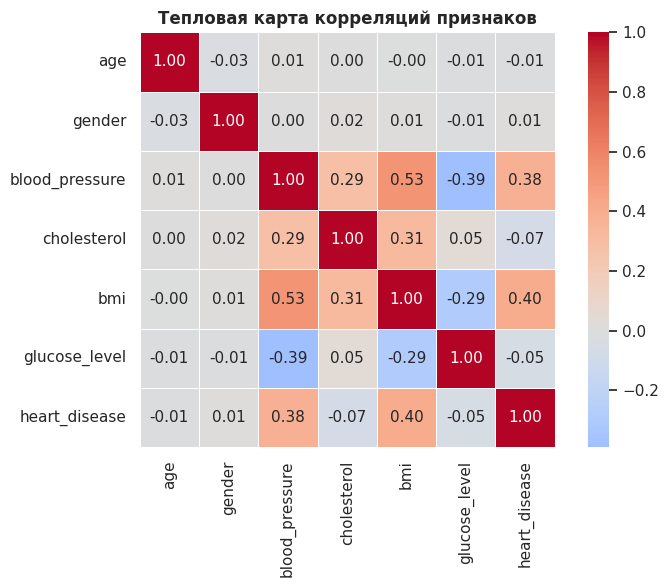

In [6]:
clinical_features = ['age', 'gender', 'blood_pressure', 'cholesterol', 'bmi', 'glucose_level']
df_clean = df[clinical_features + ['heart_disease']].copy()

df_clean['gender'] = df_clean['gender'].map({'Male': 1, 'Female': 0}).astype(int)

plt.figure(figsize=(10, 3))
sns.heatmap(df_clean.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Тепловая карта пропусков в данных (желтые полосы = пропуск)', fontsize=12, fontweight='bold')
plt.show()

print(f"Всего пропусков (NaN): {df_clean.isna().sum().sum()}")

n_start = len(df_clean)
df_clean = df_clean[
    (df_clean['glucose_level'] > 0) &
    (df_clean['blood_pressure'] > 40) &
    (df_clean['bmi'] > 10)
].reset_index(drop=True)

print(f"Удалено строк с отрицательным сахаром и физическими аномалиями: {n_start - len(df_clean)}")

numeric_cols = ['blood_pressure', 'cholesterol', 'bmi', 'glucose_level']

def get_iqr_bounds(series, k=1.5):
    q25, q75 = series.quantile([0.25, 0.75])
    iqr = q75 - q25
    return q25 - k * iqr, q75 + k * iqr

outliers_bool_df = pd.DataFrame(index=df_clean.index)
for col in numeric_cols:
    lo, hi = get_iqr_bounds(df_clean[col], k=1.5)
    outliers_bool_df[col] = (df_clean[col] < lo) | (df_clean[col] > hi)

plt.figure(figsize=(10, 4))
sns.heatmap(outliers_bool_df.T, cmap='Blues', cbar=True, yticklabels=numeric_cols, xticklabels=False)
plt.title('Тепловая карта выбросов по признакам (синие полосы = выбросы)', fontsize=12, fontweight='bold')
plt.xlabel('Пациенты (индексы строк)')
plt.ylabel('Признаки')
plt.show()

mask_any_outlier = outliers_bool_df.any(axis=1)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df_clean[col], ax=axes[0, i], color='#8fb8de')
    axes[0, i].set_title(f'ДО: {col}')

n_before_filter = len(df_clean)
df_clean = df_clean[~mask_any_outlier].reset_index(drop=True)

for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df_clean[col], ax=axes[1, i], color='#5cb85c')
    axes[1, i].set_title(f'ПОСЛЕ: {col}')

plt.suptitle('Сравнение распределений ДО (синие) и ПОСЛЕ (зеленые) удаления выбросов (1.5*IQR)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f"Удалено строк со статистическими выбросами (1.5*IQR): {mask_any_outlier.sum()}")
print(f"Итоговый размер чистой выборки: {len(df_clean)} строк")
print("\nБаланс классов (0 - здоров, 1 - болен):")
print((df_clean['heart_disease'].value_counts(normalize=True) * 100).round(2).to_string())

plt.figure(figsize=(8, 6))
corr = df_clean.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=0.5)
plt.title('Тепловая карта корреляций признаков', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Формирование набора признаков, разделение выборки и стандартизация

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_clean.drop(columns=['heart_disease'])
y = df_clean['heart_disease']

print("=== ФОРМИРОВАНИЕ ПРИЗНАКОВ ===")
print(f"Целевая переменная (y): '{y.name}'")
print(f"Список признаков (X): {list(X.columns)}")
print(f"Размерность матрицы X: {X.shape} (строк/пациентов, столбцов/признаков)")
print(f"Размерность вектора y: {y.shape}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\n=== РАЗДЕЛЕНИЕ ВЫБОРКИ (75% / 25%) ===")
print(f"Обучающая выборка (X_train): {X_train.shape[0]} пациентов")
print(f"Тестовая выборка  (X_test) : {X_test.shape[0]} пациентов")

train_share = (y_train.mean() * 100).round(2)
test_share = (y_test.mean() * 100).round(2)
print(f"Доля больных в обучении (train): {train_share}%")
print(f"Доля больных в тесте     (test) : {test_share}% (пропорции строго сохранены)")

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

scaling_check = pd.DataFrame({
    'Среднее (до)': X_train.mean().round(2),
    'Среднее (после)': X_train_scaled.mean(axis=0).round(3),
    'Std (до)': X_train.std().round(2),
    'Std (после)': X_train_scaled.std(axis=0).round(3)
}, index=X.columns)

print("\n=== РЕЗУЛЬТАТЫ СТАНДАРТИЗАЦИИ (Обучающая выборка) ===")
print("Должно быть: Среднее ≈ 0.000, Стандартное отклонение (std) = 1.000:")
print(scaling_check.to_string())

=== ФОРМИРОВАНИЕ ПРИЗНАКОВ ===
Целевая переменная (y): 'heart_disease'
Список признаков (X): ['age', 'gender', 'blood_pressure', 'cholesterol', 'bmi', 'glucose_level']
Размерность матрицы X: (5754, 6) (строк/пациентов, столбцов/признаков)
Размерность вектора y: (5754,)

=== РАЗДЕЛЕНИЕ ВЫБОРКИ (75% / 25%) ===
Обучающая выборка (X_train): 4315 пациентов
Тестовая выборка  (X_test) : 1439 пациентов
Доля больных в обучении (train): 53.26%
Доля больных в тесте     (test) : 53.23% (пропорции строго сохранены)

=== РЕЗУЛЬТАТЫ СТАНДАРТИЗАЦИИ (Обучающая выборка) ===
Должно быть: Среднее ≈ 0.000, Стандартное отклонение (std) = 1.000:
                Среднее (до)  Среднее (после)  Std (до)  Std (после)
age                    48.89              0.0     17.93          1.0
gender                  0.51              0.0      0.50          1.0
blood_pressure        101.16              0.0     30.43          1.0
cholesterol           208.81             -0.0     97.94          1.0
bmi                    2

## 4. Построение и обучение моделей классификации

In [8]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

models = {
    'Логистическая регрессия': LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),
    'Метод опорных векторов (SVM)': SVC(
        kernel='rbf',
        probability=True,
        random_state=RANDOM_STATE
    ),
    'Дерево решений (CART)': DecisionTreeClassifier(
        max_depth=4,
        criterion='gini',
        random_state=RANDOM_STATE
    )
}

trained_models = {}

print("=== ОБУЧЕНИЕ МОДЕЛЕЙ ===")
for name, model in models.items():
    start_time = time.time()

    model.fit(X_train_scaled, y_train)

    elapsed_time = time.time() - start_time
    trained_models[name] = model

    print(f"✓ Модель '{name}' успешно обучена за {elapsed_time:.3f} сек.")

print("\nВсе 3 модели обучены и готовы к тестированию!")

=== ОБУЧЕНИЕ МОДЕЛЕЙ ===
✓ Модель 'Логистическая регрессия' успешно обучена за 0.016 сек.
✓ Модель 'Метод опорных векторов (SVM)' успешно обучена за 1.611 сек.
✓ Модель 'Дерево решений (CART)' успешно обучена за 0.021 сек.

Все 3 модели обучены и готовы к тестированию!


## 5. Оценка качества и сравнительный анализ моделей

=== СРАВНИТЕЛЬНАЯ ТАБЛИЦА КАЧЕСТВА МОДЕЛЕЙ ===
                      Модель  Accuracy  Precision  Recall  F1-score  ROC-AUC
Метод опорных векторов (SVM)    0.8937     0.8885  0.9151    0.9016   0.9596
       Дерево решений (CART)    0.8700     0.8824  0.8721    0.8772   0.9275
     Логистическая регрессия    0.7144     0.7326  0.7298    0.7312   0.8081

Детальный отчет для: Логистическая регрессия
              precision    recall  f1-score   support

  Здоров (0)      0.694     0.697     0.695       673
   Болен (1)      0.733     0.730     0.731       766

    accuracy                          0.714      1439
   macro avg      0.713     0.713     0.713      1439
weighted avg      0.714     0.714     0.714      1439


Детальный отчет для: Метод опорных векторов (SVM)
              precision    recall  f1-score   support

  Здоров (0)      0.900     0.869     0.884       673
   Болен (1)      0.888     0.915     0.902       766

    accuracy                          0.894      1439
   

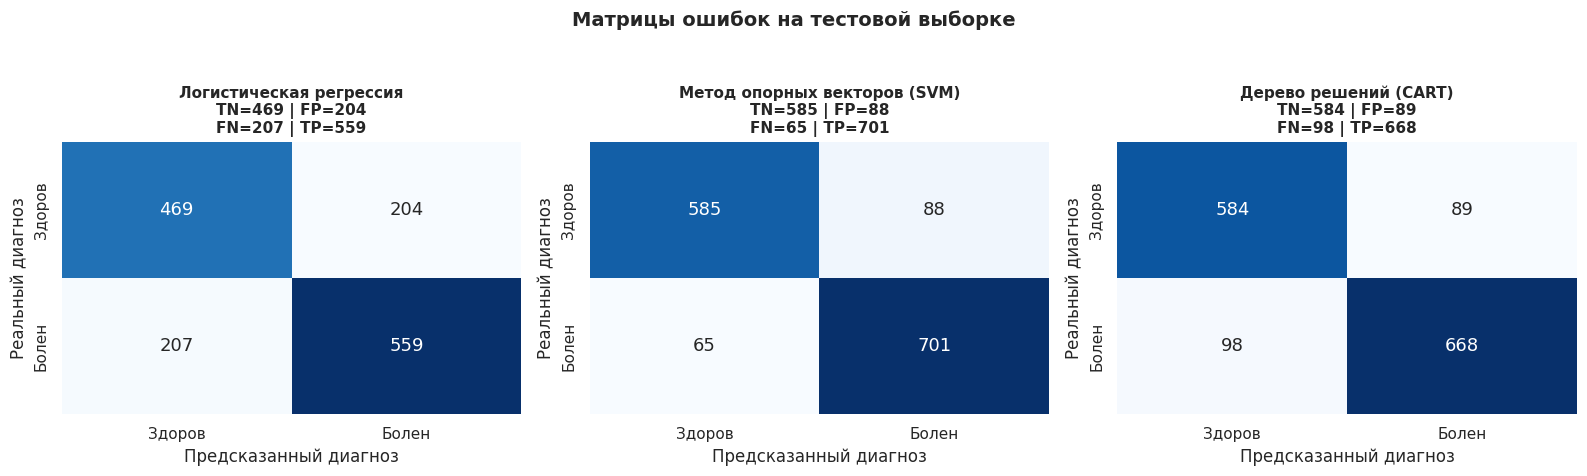

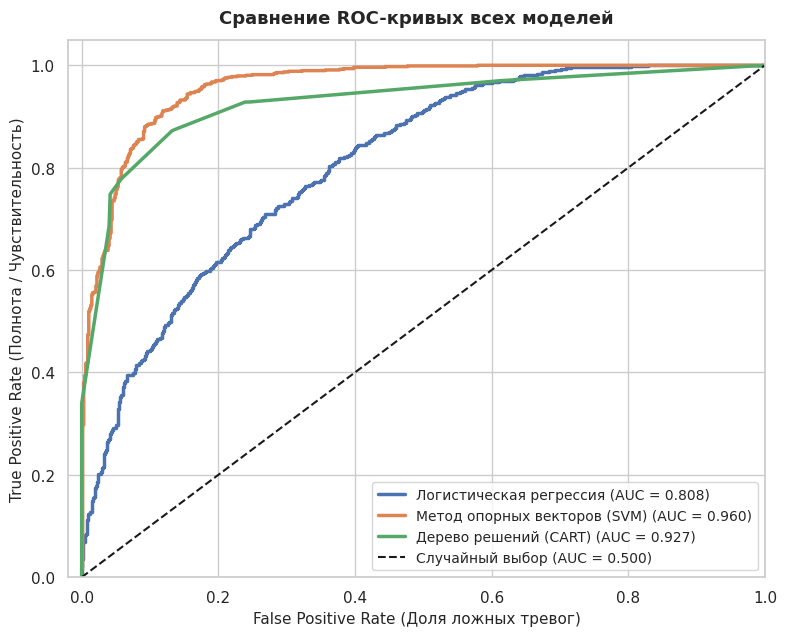

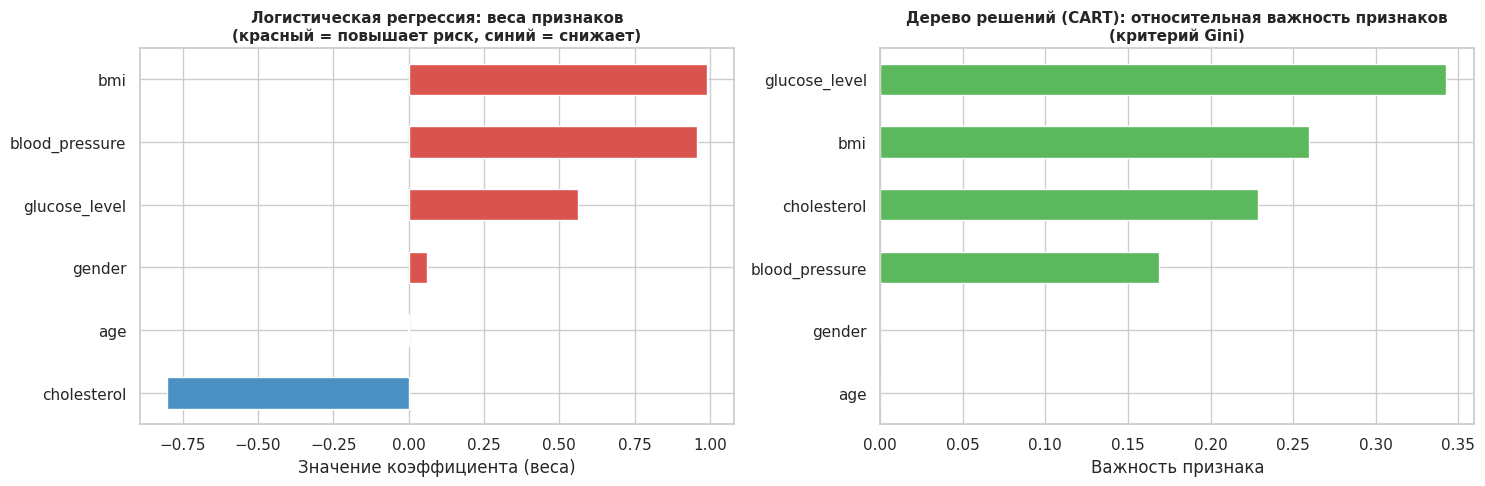

Лучшая модель: Метод опорных векторов (SVM) с показателем ROC-AUC = 0.9596 и Accuracy = 0.8937


In [10]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report)

results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test_scaled)

    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

    results.append({
        'Модель': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-score': round(f1, 4),
        'ROC-AUC': round(roc_auc, 4)
    })

comparison_df = pd.DataFrame(results).sort_values(by='ROC-AUC', ascending=False)
print("=== СРАВНИТЕЛЬНАЯ ТАБЛИЦА КАЧЕСТВА МОДЕЛЕЙ ===")
print(comparison_df.to_string(index=False))

for name, model in trained_models.items():
    print(f"\n{'='*55}\nДетальный отчет для: {name}\n{'='*55}")
    print(classification_report(y_test, model.predict(X_test_scaled),
                                target_names=['Здоров (0)', 'Болен (1)'], digits=3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, model) in zip(axes, trained_models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Здоров', 'Болен'],
                yticklabels=['Здоров', 'Болен'], annot_kws={'size': 13})

    ax.set_title(f"{name}\nTN={tn} | FP={fp}\nFN={fn} | TP={tp}", fontsize=11, fontweight='bold')
    ax.set_xlabel('Предсказанный диагноз')
    ax.set_ylabel('Реальный диагноз')

plt.suptitle('Матрицы ошибок на тестовой выборке', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6.5))

for name, model in trained_models.items():
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, lw=2.5, label=f'{name} (AUC = {auc_val:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Случайный выбор (AUC = 0.500)')
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (Доля ложных тревог)', fontsize=11)
plt.ylabel('True Positive Rate (Полнота / Чувствительность)', fontsize=11)
plt.title('Сравнение ROC-кривых всех моделей', fontsize=13, fontweight='bold', pad=12)
plt.legend(loc='lower right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

logreg = trained_models['Логистическая регрессия']
coef_series = pd.Series(logreg.coef_[0], index=X.columns).sort_values()
colors = ['#d9534f' if c > 0 else '#4a90c2' for c in coef_series]
coef_series.plot(kind='barh', ax=axes[0], color=colors)
axes[0].set_title('Логистическая регрессия: веса признаков\n(красный = повышает риск, синий = снижает)',
                  fontsize=11, fontweight='bold')
axes[0].set_xlabel('Значение коэффициента (веса)')

cart = trained_models['Дерево решений (CART)']
imp_series = pd.Series(cart.feature_importances_, index=X.columns).sort_values()
imp_series.plot(kind='barh', ax=axes[1], color='#5cb85c')
axes[1].set_title('Дерево решений (CART): относительная важность признаков\n(критерий Gini)',
                  fontsize=11, fontweight='bold')
axes[1].set_xlabel('Важность признака')

plt.tight_layout()
plt.show()

best_model_row = comparison_df.iloc[0]
print(f"Лучшая модель: {best_model_row['Модель']} с показателем ROC-AUC = {best_model_row['ROC-AUC']} и Accuracy = {best_model_row['Accuracy']}")